# Exploración de datos: BigMart Sales

Este notebook reproduce con código los hallazgos de la sección 4 de
`docs/decisiones.md`. El dataset tiene 8,523 filas, una por producto y tienda,
y la variable objetivo es `Item_Units = Item_Outlet_Sales / Item_MRP`: las
unidades vendidas, que es lo que hay que decidir cuántas enviar a cada tienda.

Los datos se cargan con el catálogo de Kedro. Antes de abrirlo hay que correr
`kedro run --pipeline data_processing` para generar `bigmart_features`.

In [1]:
%%capture
%load_ext kedro.ipython

In [2]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from bigmart_surtido.estilo import (
    COLOR_FONDO,
    COLOR_PRODUCTO,
    COLOR_TEXTO_SECUNDARIO,
    COLOR_TIENDA,
    estilo_ejes,
    titulo,
)

plt.rcParams["figure.facecolor"] = COLOR_FONDO
plt.rcParams["figure.dpi"] = 110
logging.getLogger("kedro").setLevel(logging.WARNING)

crudos = catalog.load("bigmart_raw")  # noqa: F821
datos = catalog.load("bigmart_features")  # noqa: F821
crudos.shape, datos.shape

((8523, 12), (8523, 15))

## a. Calidad de los datos crudos

Antes de limpiar, revisamos faltantes, etiquetas inconsistentes, visibilidades
en cero y duplicados en `bigmart_raw`.

In [3]:
faltantes = crudos.isna().sum()
faltantes[faltantes > 0].rename("faltantes").to_frame()

,faltantes
Item_Weight,1463
Outlet_Size,2410


In [4]:
crudos["Item_Fat_Content"].value_counts().rename("filas").to_frame()

,filas
Item_Fat_Content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112


In [5]:
pd.Series(
    {
        "Visibilidad en cero": int((crudos["Item_Visibility"] == 0).sum()),
        "Filas duplicadas": int(crudos.duplicated().sum()),
    },
    name="filas",
).to_frame()

,filas
Visibilidad en cero,526
Filas duplicadas,0


**Qué se ve.** `Item_Weight` tiene 1,463 faltantes y `Outlet_Size` 2,410.
`Item_Fat_Content` usa cinco etiquetas para dos valores reales (*Low Fat* y
*Regular*), hay 526 productos con visibilidad 0 (un producto que se vende no
puede tener visibilidad nula) y no hay filas duplicadas.

**Para el negocio.** Son errores de captura, no información: el pipeline
`data_processing` unifica las etiquetas e imputa los faltantes y las
visibilidades en cero. Los faltantes de `Outlet_Size` son de tiendas completas,
así que el tamaño de esas tiendas es un supuesto, no un dato.

## b. Ventas en Q vs unidades

Las ventas en quetzales mezclan dos cosas: cuántas unidades se venden y a qué
precio. Comparamos la relación de cada una con el precio (`Item_MRP`).

In [6]:
datos[["Item_MRP", "Item_Outlet_Sales", "Item_Units"]].corr().loc[
    "Item_MRP", ["Item_Outlet_Sales", "Item_Units"]
].rename("correlación con Item_MRP").round(3).to_frame()

,correlación con Item_MRP
Item_Outlet_Sales,0.568
Item_Units,0.011


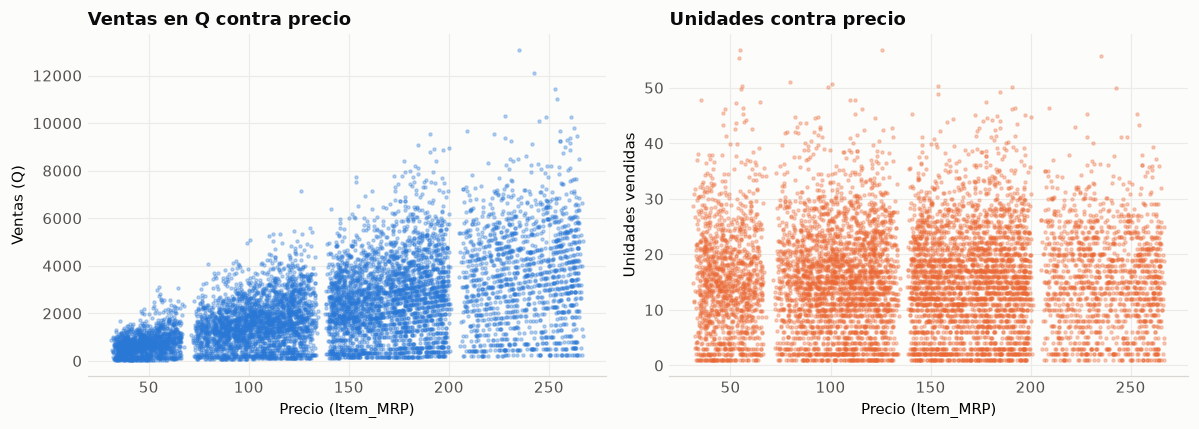

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(
    datos["Item_MRP"], datos["Item_Outlet_Sales"], s=4, alpha=0.3, color=COLOR_TIENDA
)
estilo_ejes(ax1, grilla="both")
titulo(ax1, "Ventas en Q contra precio")
ax1.set_xlabel("Precio (Item_MRP)")
ax1.set_ylabel("Ventas (Q)")
ax2.scatter(
    datos["Item_MRP"], datos["Item_Units"], s=4, alpha=0.3, color=COLOR_PRODUCTO
)
estilo_ejes(ax2, grilla="both")
titulo(ax2, "Unidades contra precio")
ax2.set_xlabel("Precio (Item_MRP)")
ax2.set_ylabel("Unidades vendidas")
fig.tight_layout()
plt.show()

**Qué se ve.** Las ventas en Q tienen una correlación de 0.57 con el precio,
pero las unidades casi no se relacionan con él (0.01). La forma de abanico de
la izquierda es la multiplicación unidades × precio.

**Para el negocio.** Un producto caro factura más por aritmética, no porque se
venda más. Para decidir cuántas unidades enviar hay que modelar unidades, no
ventas en Q.

## c. El formato define la demanda

Comparamos la distribución de unidades por formato de tienda y la razón de las
unidades medias de cada formato frente a Supermarket Type1, el formato más
común.

In [8]:
orden = ["Grocery Store", "Supermarket Type1", "Supermarket Type2", "Supermarket Type3"]
medias = datos.groupby("Outlet_Type")["Item_Units"].mean().reindex(orden)
pd.DataFrame(
    {
        "unidades medias": medias.round(2),
        "razón vs Type1": (medias / medias["Supermarket Type1"]).round(2),
    }
)

,unidades medias,razón vs Type1
Outlet_Type,,
Grocery Store,2.41,0.15
Supermarket Type1,16.34,1.00
Supermarket Type2,13.85,0.85
Supermarket Type3,26.61,1.63


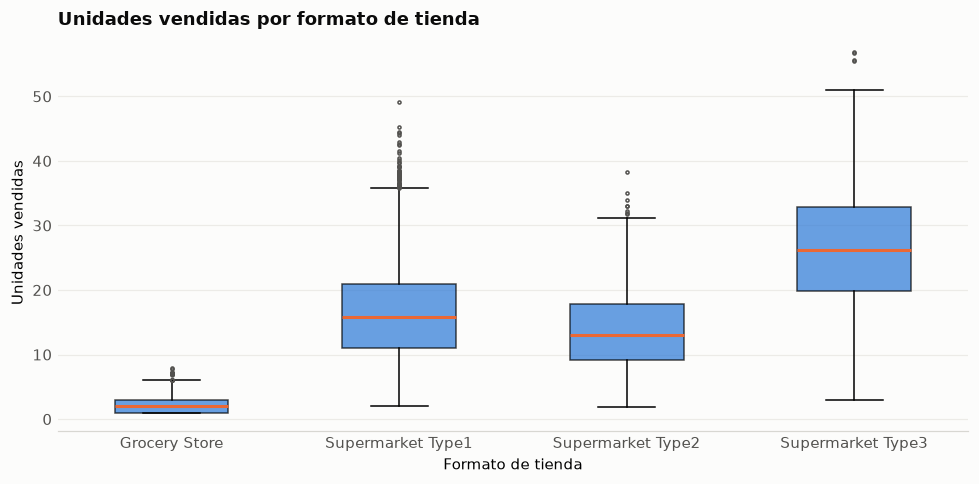

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cajas = ax.boxplot(
    [datos.loc[datos["Outlet_Type"] == f, "Item_Units"] for f in orden],
    patch_artist=True,
    widths=0.5,
    medianprops={"color": COLOR_PRODUCTO, "linewidth": 2},
    flierprops={"markersize": 2, "markeredgecolor": COLOR_TEXTO_SECUNDARIO},
)
for caja in cajas["boxes"]:
    caja.set_facecolor(COLOR_TIENDA)
    caja.set_alpha(0.7)
ax.set_xticks(range(1, len(orden) + 1), orden)
estilo_ejes(ax)
titulo(ax, "Unidades vendidas por formato de tienda")
ax.set_xlabel("Formato de tienda")
ax.set_ylabel("Unidades vendidas")
fig.tight_layout()
plt.show()

**Qué se ve.** Las Grocery venden una fracción de lo que vende un Type1, los
Type2 venden algo menos y los Type3 bastante más. Las cajas casi no se
traslapan entre Grocery y los supermercados.

**Para el negocio.** El formato de la tienda es la variable que más mueve la
demanda: la primera decisión de cuántas unidades enviar es a qué formato van.

## d. El producto no tiene señal propia

Si un producto "vendedor" lo fuera en cualquier tienda, sus unidades en un
grupo de tiendas deberían predecir sus unidades en otro. Dividimos las 6
tiendas Type1 en dos grupos (OUT013, OUT017, OUT035 vs OUT045, OUT046, OUT049),
promediamos las unidades de cada producto en cada grupo y comparamos.

In [10]:
type1 = datos[datos["Outlet_Type"] == "Supermarket Type1"]
grupo_a = ["OUT013", "OUT017", "OUT035"]
grupo_b = ["OUT045", "OUT046", "OUT049"]
por_grupo = pd.concat(
    {
        "grupo_a": type1[type1["Outlet_Identifier"].isin(grupo_a)]
        .groupby("Item_Identifier")["Item_Units"]
        .mean(),
        "grupo_b": type1[type1["Outlet_Identifier"].isin(grupo_b)]
        .groupby("Item_Identifier")["Item_Units"]
        .mean(),
    },
    axis=1,
).dropna()

top_a = por_grupo["grupo_a"] >= por_grupo["grupo_a"].quantile(0.8)
top_b = por_grupo["grupo_b"] >= por_grupo["grupo_b"].quantile(0.8)
pd.Series(
    {
        "Productos en ambos grupos": len(por_grupo),
        "Correlación entre grupos": round(
            por_grupo["grupo_a"].corr(por_grupo["grupo_b"]), 3
        ),
        "P(top 20% en B | top 20% en A)": round((top_a & top_b).sum() / top_a.sum(), 3),
    },
    name="valor",
).to_frame()

,valor
Productos en ambos grupos,1365.000
Correlación entre grupos,0.036
P(top 20% en B | top 20% en A),0.201


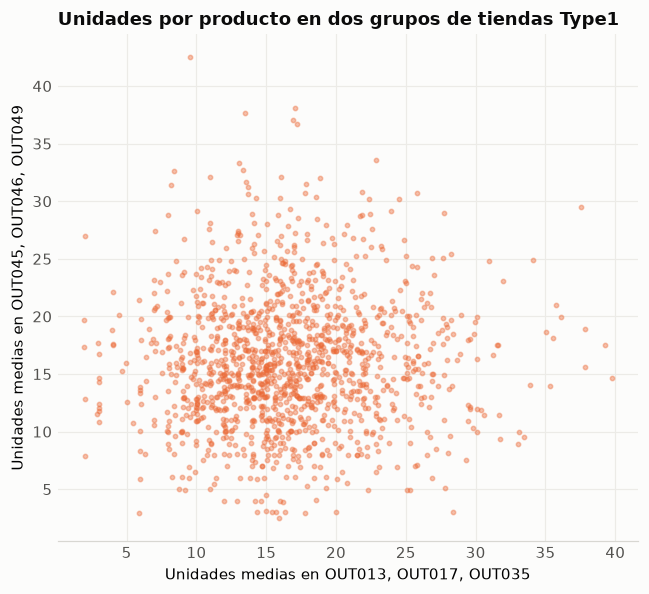

In [11]:
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(
    por_grupo["grupo_a"], por_grupo["grupo_b"], s=8, alpha=0.4, color=COLOR_PRODUCTO
)
estilo_ejes(ax, grilla="both")
titulo(ax, "Unidades por producto en dos grupos de tiendas Type1")
ax.set_xlabel("Unidades medias en OUT013, OUT017, OUT035")
ax.set_ylabel("Unidades medias en OUT045, OUT046, OUT049")
fig.tight_layout()
plt.show()

**Qué se ve.** La nube no tiene pendiente: la correlación entre grupos es
cercana a cero (0.04) y de los productos en el top 20% de un grupo solo
alrededor del 20% repite en el top del otro, lo mismo que se esperaría al azar.

**Para el negocio.** El historial de ventas de un producto en unas tiendas no
sirve para predecir cuánto venderá en otras. No vale la pena enviar más de un
producto porque "se vendió bien" en otro lado.

## e. La visibilidad no tiene efecto

La visibilidad se correlaciona negativamente con las ventas, pero eso puede
deberse a que las Grocery tienen más visibilidad por producto. Para aislar el
efecto, dentro de las tiendas Type1 restamos a unidades y visibilidad la media
de cada producto, y correlacionamos lo que queda.

In [12]:
centrados = type1[["Item_Units", "Item_Visibility"]] - type1.groupby("Item_Identifier")[
    ["Item_Units", "Item_Visibility"]
].transform("mean")
pd.Series(
    {
        "Correlación cruda visibilidad-ventas (todas las tiendas)": round(
            datos["Item_Visibility"].corr(datos["Item_Outlet_Sales"]), 3
        ),
        "Correlación centrada visibilidad-unidades (Type1)": round(
            centrados["Item_Visibility"].corr(centrados["Item_Units"]), 3
        ),
    },
    name="correlación",
).to_frame()

,correlación
Correlación cruda visibilidad-ventas (todas las tiendas),-0.121
Correlación centrada visibilidad-unidades (Type1),0.010


**Qué se ve.** Cuando se compara al mismo producto en distintas tiendas Type1,
tener más visibilidad no se asocia con vender más unidades (correlación
cercana a cero).

**Para el negocio.** La visibilidad no es una palanca útil para planificar
envíos; la correlación negativa que aparece en los datos crudos es un efecto
del formato de tienda.

## f. Categorías por formato

¿Alguna categoría rinde mejor en un formato que en otro? Calculamos un índice:
unidades medias de cada `Item_Type` en cada formato dividido entre el promedio
del formato (1 = igual al promedio). Luego un ANOVA de una vía por formato
para ver si las categorías difieren.

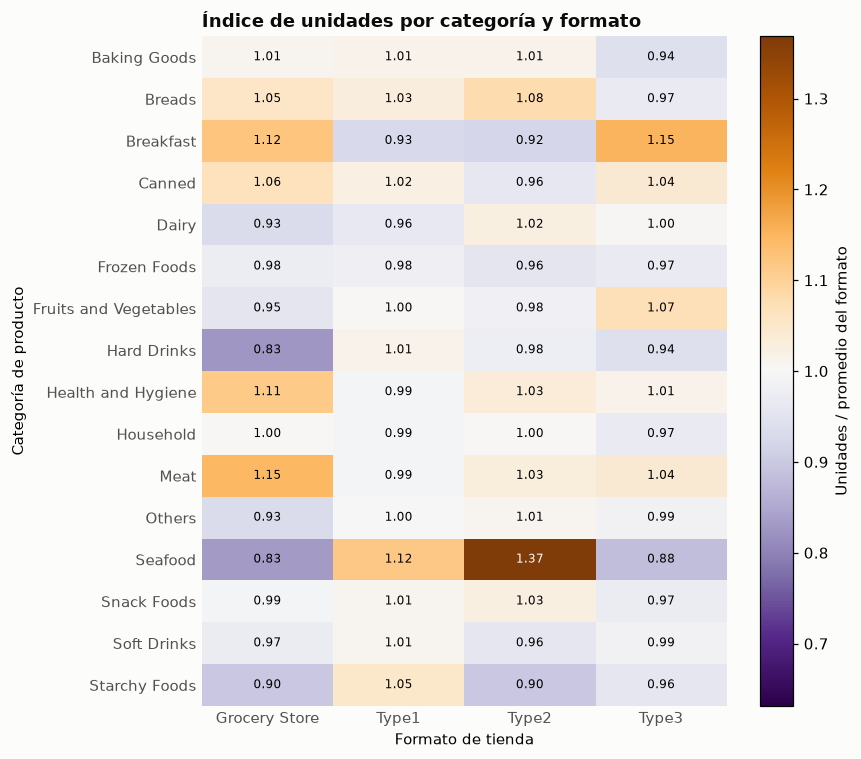

In [13]:
indice = (
    datos.groupby(["Item_Type", "Outlet_Type"])["Item_Units"].mean().unstack()
    / datos.groupby("Outlet_Type")["Item_Units"].mean()
)[orden]

fig, ax = plt.subplots(figsize=(8, 7))
limite = np.abs(indice.to_numpy() - 1).max()
mapa = ax.imshow(indice, cmap="PuOr_r", vmin=1 - limite, vmax=1 + limite, aspect="auto")
ax.set_xticks(range(len(orden)), [f.replace("Supermarket ", "") for f in orden])
ax.set_yticks(range(len(indice)), indice.index)
for i in range(indice.shape[0]):
    for j in range(indice.shape[1]):
        valor = indice.iloc[i, j]
        color = "white" if abs(valor - 1) > 0.6 * limite else "black"
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8, color=color)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.tick_params(length=0, colors=COLOR_TEXTO_SECUNDARIO)
titulo(ax, "Índice de unidades por categoría y formato")
ax.set_xlabel("Formato de tienda")
ax.set_ylabel("Categoría de producto")
fig.colorbar(mapa, ax=ax, label="Unidades / promedio del formato")
fig.tight_layout()
plt.show()

In [14]:
pd.Series(
    {
        formato: round(
            stats.f_oneway(
                *[g["Item_Units"] for _, g in grupo.groupby("Item_Type")]
            ).pvalue,
            3,
        )
        for formato, grupo in datos.groupby("Outlet_Type")
    },
    name="p-valor ANOVA",
).reindex(orden).to_frame()

,p-valor ANOVA
Grocery Store,0.443
Supermarket Type1,0.593
Supermarket Type2,0.858
Supermarket Type3,0.464


**Qué se ve.** El mapa es casi uniforme: los índices se mueven alrededor de 1
sin un patrón por formato, y el ANOVA dentro de cada formato da p-valores entre
0.44 y 0.86, lejos de 0.05.

**Para el negocio.** Ninguna categoría se vende mejor en un formato que en
otro. No hace falta un surtido distinto por formato; de la categoría solo
importa si es perecedera, porque eso cambia el costo de equivocarse.

## g. Tamaño y ubicación

¿Influyen el tamaño de la tienda y el tier de ubicación? Revisamos las 10
tiendas con su formato, tamaño, tier y unidades medias.

In [15]:
tiendas = (
    datos.groupby("Outlet_Identifier")
    .agg(
        formato=("Outlet_Type", "first"),
        tamaño=("Outlet_Size", "first"),
        tier=("Outlet_Location_Type", "first"),
        unidades_medias=("Item_Units", "mean"),
    )
    .round({"unidades_medias": 2})
    .sort_values(["formato", "tamaño", "tier"])
)
tiendas

,formato,tamaño,tier,unidades_medias
Outlet_Identifier,,,,
OUT019,Grocery Store,Small,Tier 1,2.44
OUT010,Grocery Store,Small,Tier 3,2.38
OUT013,Supermarket Type1,High,Tier 3,16.00
OUT049,Supermarket Type1,Medium,Tier 1,16.63
OUT046,Supermarket Type1,Small,Tier 1,16.19
OUT017,Supermarket Type1,Small,Tier 2,16.66
OUT035,Supermarket Type1,Small,Tier 2,16.97
OUT045,Supermarket Type1,Small,Tier 2,15.58
OUT018,Supermarket Type2,Medium,Tier 3,13.85


In [16]:
tiendas.groupby(["formato", "tamaño", "tier"]).size().rename("tiendas").to_frame()

tiendas
formato           tamaño tier           
Grocery Store     Small  Tier 1        1
                         Tier 3        1
Supermarket Type1 High   Tier 3        1
                  Medium Tier 1        1
                  Small  Tier 1        1
                         Tier 2        3
Supermarket Type2 Medium Tier 3        1
Supermarket Type3 Medium Tier 3        1

**Qué se ve.** Con 10 tiendas, casi cada combinación formato × tamaño × tier
corresponde a una sola tienda, así que no se puede separar el efecto del
tamaño o del tier del de la tienda misma. Dentro de Type1 las unidades medias
están entre 15.6 y 17.0 sin importar tamaño ni tier. Además, el tamaño de
OUT010, OUT017 y OUT045 fue imputado.

**Para el negocio.** Con estos datos no se puede afirmar que una tienda grande
o urbana necesite más inventario que otra del mismo formato. La variable útil
para planificar envíos es el formato.